# Real Estate Investment Advisor — Data Preprocessing & EDA
**Project:** Predicting Property Profitability & Future Value  
**Dataset:** `data/india_housing_prices.csv`  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn

> Run this notebook from the project root. The notebook saves cleaned data, tables, and figures into `outputs/`. This is an analytical workflow; investment labels and five-year projections depend on explicit assumptions and are not financial advice.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
# If launched from notebooks/, use the parent project directory.
if not (ROOT / "data" / "india_housing_prices.csv").exists() and (ROOT.parent / "data" / "india_housing_prices.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "india_housing_prices.csv"
OUT = ROOT / "outputs"
FIG = OUT / "figures"
OUT.mkdir(exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head())


Dataset shape: 250,000 rows × 23 columns


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


## 1. Data audit — shape, types, missingness, duplicates

In [2]:
audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(3),
    "unique_values": df_raw.nunique(dropna=False)
}).sort_values("missing_pct", ascending=False)
display(audit)
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate IDs:", df_raw["ID"].duplicated().sum() if "ID" in df_raw else "ID column absent")
display(df_raw.describe(include="all").T)
audit.to_csv(OUT / "data_audit.csv")


,dtype,missing_count,missing_pct,unique_values
ID,int64,0,0.00,250000
State,str,0,0.00,20
City,str,0,0.00,42
Locality,str,0,0.00,500
Property_Type,str,0,0.00,3
BHK,int64,0,0.00,5
Size_in_SqFt,int64,0,0.00,4501
Price_in_Lakhs,float64,0,0.00,48700
Price_per_SqFt,float64,0,0.00,100
Year_Built,int64,0,0.00,34


Exact duplicate rows: 0
Duplicate IDs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,"250,000.00",NaN,NaN,NaN,"125,000.50","72,168.93",1.00,"62,500.75","125,000.50","187,500.25","250,000.00"
State,250000,20,Odisha,12681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,250000,42,Coimbatore,6461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality,250000,500,Locality_296,567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Property_Type,250000,3,Villa,83744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BHK,"250,000.00",NaN,NaN,NaN,3.00,1.42,1.00,2.00,3.00,4.00,5.00
Size_in_SqFt,"250,000.00",NaN,NaN,NaN,"2,749.81","1,300.61",500.00,"1,623.00","2,747.00","3,874.00","5,000.00"
Price_in_Lakhs,"250,000.00",NaN,NaN,NaN,254.59,141.35,10.00,132.55,253.87,376.88,500.00
Price_per_SqFt,"250,000.00",NaN,NaN,NaN,0.13,0.13,0.00,0.05,0.09,0.16,0.99
Year_Built,"250,000.00",NaN,NaN,NaN,"2,006.52",9.81,"1,990.00","1,998.00","2,007.00","2,015.00","2,023.00"


## 2. Cleaning and validation
We preserve the raw file, remove exact duplicate rows, normalize text fields, coerce expected numeric columns, and flag impossible or inconsistent values. Missing values are imputed using medians for numeric fields and the most frequent category for categorical fields. Values are not silently clipped; suspicious rows are reported so decisions remain auditable.

In [3]:
df = df_raw.copy()
df = df.drop_duplicates().copy()

# Normalize text columns to consistent whitespace; preserve category spelling otherwise.
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "NA": pd.NA, "N/A": pd.NA, "null": pd.NA, "None": pd.NA})

numeric_expected = [
    "ID", "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt",
    "Year_Built", "Floor_No", "Total_Floors", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals"
]
for col in numeric_expected:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Record domain-rule violations before remediation.
rules = {
    "nonpositive_size": df["Size_in_SqFt"].le(0) if "Size_in_SqFt" in df else pd.Series(False, index=df.index),
    "nonpositive_price": df["Price_in_Lakhs"].le(0) if "Price_in_Lakhs" in df else pd.Series(False, index=df.index),
    "invalid_bhk": df["BHK"].le(0) if "BHK" in df else pd.Series(False, index=df.index),
    "year_in_future": df["Year_Built"].gt(pd.Timestamp.today().year) if "Year_Built" in df else pd.Series(False, index=df.index),
    "negative_floor": df["Floor_No"].lt(0) if "Floor_No" in df else pd.Series(False, index=df.index),
    "floors_inconsistent": (df["Total_Floors"].lt(df["Floor_No"])) if {"Total_Floors", "Floor_No"}.issubset(df.columns) else pd.Series(False, index=df.index),
}
quality_flags = pd.DataFrame({k: v.astype(bool) for k, v in rules.items()})
quality_flags["any_rule_violation"] = quality_flags.any(axis=1)
display(quality_flags.sum().to_frame("flagged_rows"))
quality_flags.sum().to_csv(OUT / "quality_rule_counts.csv")

# Replace invalid numeric values with missing so they can be imputed consistently.
for col in ["Size_in_SqFt", "Price_in_Lakhs", "BHK", "Nearby_Schools", "Nearby_Hospitals", "Parking_Space"]:
    if col in df and pd.api.types.is_numeric_dtype(df[col]):
        df.loc[df[col] < 0, col] = np.nan
if "Year_Built" in df:
    df.loc[df["Year_Built"] > pd.Timestamp.today().year, "Year_Built"] = np.nan

# Derived age uses current year; if age and year-built disagree, recompute from Year_Built when available.
current_year = pd.Timestamp.today().year
if "Year_Built" in df:
    computed_age = current_year - df["Year_Built"]
    df["Age_of_Property"] = computed_age.where(df["Year_Built"].notna(), df.get("Age_of_Property"))

# Impute numeric columns with median, categorical with mode.
for col in df.select_dtypes(include=["number"]).columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())
for col in df.select_dtypes(include=["object", "string", "category"]).columns:
    if df[col].isna().any():
        mode = df[col].mode(dropna=True)
        df[col] = df[col].fillna(mode.iloc[0] if not mode.empty else "Unknown")

# Validate/recalculate price per square foot where possible.
# Price is in lakhs; conversion to rupees is price_lakhs * 100,000.
valid_area = df["Size_in_SqFt"].gt(0)
valid_price = df["Price_in_Lakhs"].gt(0)
calculated_ppsf = (df["Price_in_Lakhs"] * 100_000) / df["Size_in_SqFt"]
# The supplied Price_per_SqFt scale appears inconsistent in sample rows; preserve original in a separate column.
df["Price_per_SqFt_Original"] = df.get("Price_per_SqFt", np.nan)
df["Price_per_SqFt"] = np.where(valid_area & valid_price, calculated_ppsf, np.nan)
df["Price_per_SqFt"] = df["Price_per_SqFt"].fillna(df["Price_per_SqFt"].median())

df.to_csv(OUT / "cleaned_housing_data.csv", index=False)
print(f"Cleaned dataset saved: {OUT / 'cleaned_housing_data.csv'}")
print("Cleaned shape:", df.shape)
print("Remaining missing cells:", int(df.isna().sum().sum()))


,flagged_rows
nonpositive_size,0
nonpositive_price,0
invalid_bhk,0
year_in_future,0
negative_floor,0
floors_inconsistent,116304
any_rule_violation,116304


Cleaned dataset saved: C:\Users\Eklavya\Desktop\real_estate_investment_advisor\outputs\cleaned_housing_data.csv
Cleaned shape: (250000, 24)
Remaining missing cells: 0


## 3. Feature engineering
Create transparent features that are useful for analysis. We avoid using `ID` as a predictive feature. The investment label is defined by the project brief's price-vs-median option: a property is labelled potentially attractive when its price per square foot is at or below the median for its city. This is a proxy label, not verified investment performance.

In [4]:
df["Amenities_Count"] = (
    df["Amenities"].fillna("").astype(str)
      .apply(lambda s: len([x for x in s.split(",") if x.strip()]))
)
df["Has_Parking"] = df["Parking_Space"].astype(str).str.lower().isin(["yes", "1", "true"]).astype(int)
df["Has_Security"] = df["Security"].astype(str).str.lower().isin(["yes", "1", "true", "gated", "cctv", "guard"]).astype(int)
city_median_ppsf = df.groupby("City")["Price_per_SqFt"].transform("median")
df["Good_Investment"] = (df["Price_per_SqFt"] <= city_median_ppsf).astype(int)
df["Good_Investment_Label_Definition"] = "Price_per_SqFt <= city median"

display(df[["City", "Price_in_Lakhs", "Size_in_SqFt", "Price_per_SqFt", "Amenities_Count", "Good_Investment"]].head())
df["Good_Investment"].value_counts(normalize=True).rename("proportion").to_csv(OUT / "investment_label_balance.csv")


,City,Price_in_Lakhs,Size_in_SqFt,Price_per_SqFt,Amenities_Count,Good_Investment
0,Chennai,489.76,"4,740.00","10,332.49",5,0
1,Pune,195.52,"2,364.00","8,270.73",5,1
2,Ludhiana,183.79,"3,642.00","5,046.40",4,1
3,Jodhpur,300.29,"2,741.00","10,955.49",5,0
4,Jaipur,182.90,"4,823.00","3,792.25",5,1


## 4. EDA — questions 1–5: price, size, price/sqft, relationships, outliers

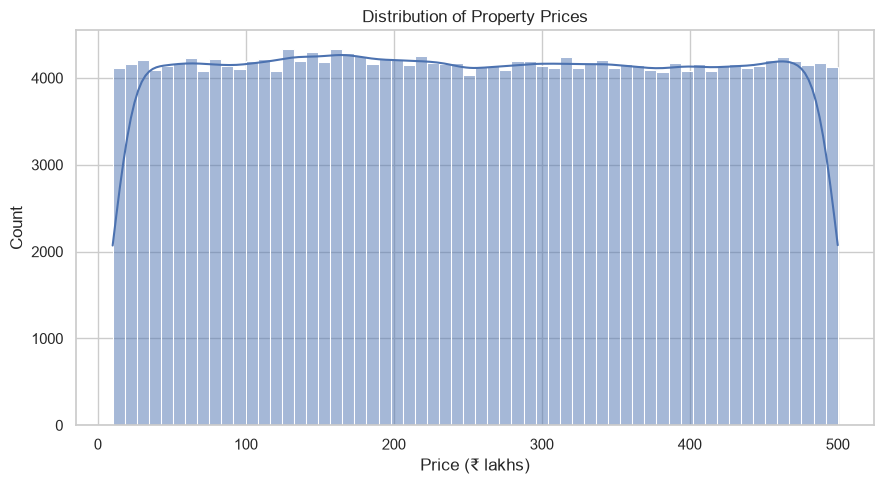

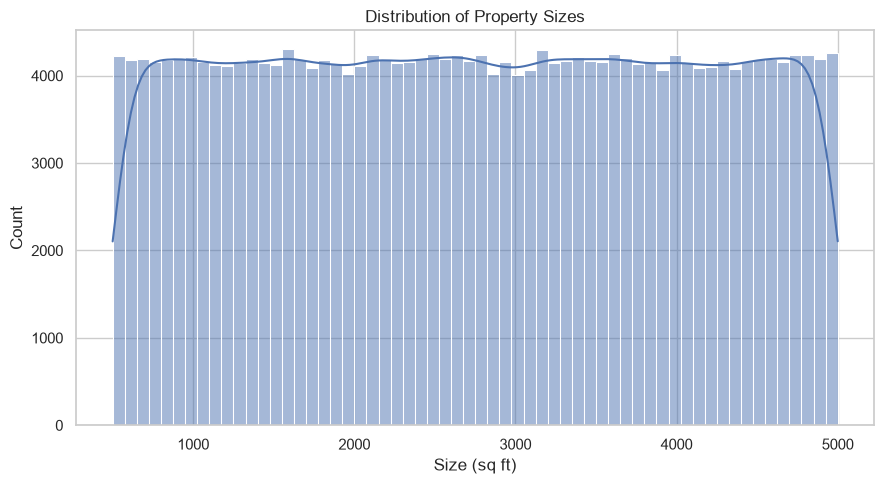

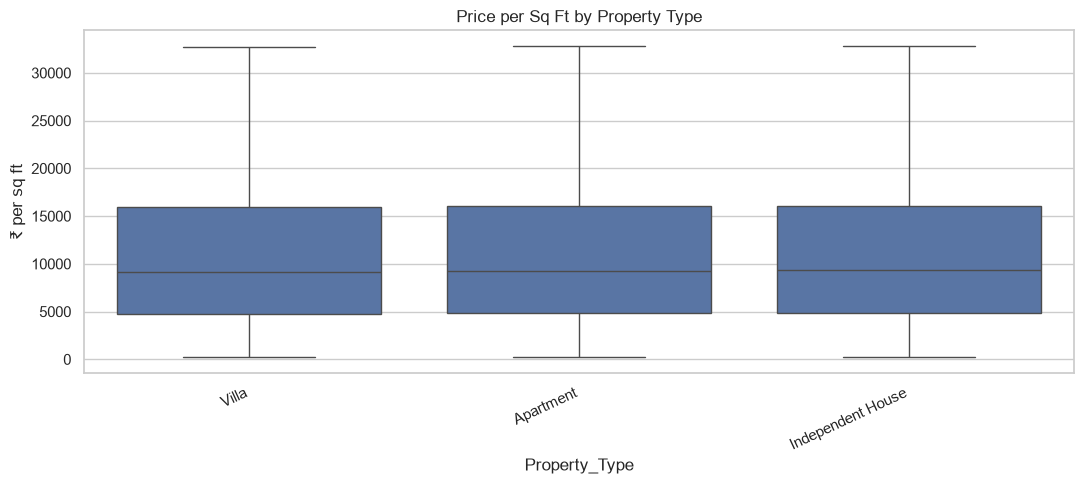

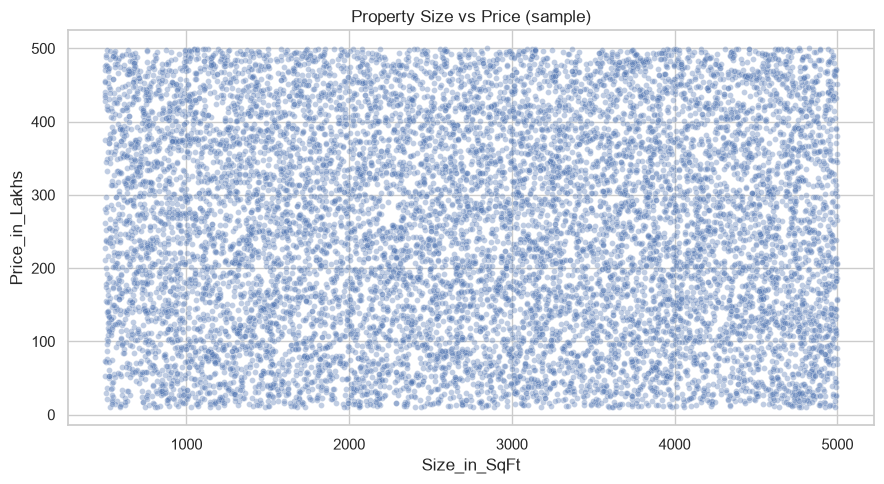

,feature,q1,q3,lower_bound,upper_bound,outlier_count
0,Price_per_SqFt,"4,802.84","15,987.39","-11,973.98","32,764.21",19723
1,Size_in_SqFt,"1,623.00","3,874.00","-1,753.50","7,250.50",0
2,Price_in_Lakhs,132.55,376.88,-233.94,743.38,0


In [5]:
# Q1. Distribution of property prices
plt.figure(figsize=(9, 5))
sns.histplot(df["Price_in_Lakhs"], bins=60, kde=True)
plt.title("Distribution of Property Prices")
plt.xlabel("Price (₹ lakhs)")
plt.tight_layout(); plt.savefig(FIG / "01_price_distribution.png", dpi=160); plt.show()

# Q2. Distribution of property sizes
plt.figure(figsize=(9, 5))
sns.histplot(df["Size_in_SqFt"], bins=60, kde=True)
plt.title("Distribution of Property Sizes")
plt.xlabel("Size (sq ft)")
plt.tight_layout(); plt.savefig(FIG / "02_size_distribution.png", dpi=160); plt.show()

# Q3. Price per sq ft by property type
plt.figure(figsize=(11, 5))
order = df.groupby("Property_Type")["Price_per_SqFt"].median().sort_values().index
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt", order=order, showfliers=False)
plt.xticks(rotation=25, ha="right"); plt.title("Price per Sq Ft by Property Type")
plt.ylabel("₹ per sq ft")
plt.tight_layout(); plt.savefig(FIG / "03_ppsf_by_property_type.png", dpi=160); plt.show()

# Q4. Relationship between size and price (sample for plotting performance)
plot_sample = df.sample(min(12000, len(df)), random_state=42)
plt.figure(figsize=(9, 5))
sns.scatterplot(data=plot_sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=.35, s=18)
plt.title("Property Size vs Price (sample)")
plt.tight_layout(); plt.savefig(FIG / "04_size_vs_price.png", dpi=160); plt.show()

# Q5. IQR-based outlier counts, reported rather than automatically deleted.
outlier_rows = []
for col in ["Price_per_SqFt", "Size_in_SqFt", "Price_in_Lakhs"]:
    q1, q3 = df[col].quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"feature": col, "q1": q1, "q3": q3, "lower_bound": lo, "upper_bound": hi,
                         "outlier_count": int(((df[col] < lo) | (df[col] > hi)).sum())})
outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)
outlier_report.to_csv(OUT / "outlier_report.csv", index=False)


## 5. EDA — questions 6–10: geography, locality, BHK and expensive localities

,State,Price_per_SqFt
0,Karnataka,"13,252.20"
1,Andhra Pradesh,"13,201.58"
2,Uttar Pradesh,"13,142.52"
3,Tamil Nadu,"13,132.42"
4,Telangana,"13,093.10"
5,Gujarat,"13,091.15"
6,Assam,"13,084.02"
7,Maharashtra,"13,070.13"
8,Madhya Pradesh,"13,069.03"
9,Haryana,"13,068.74"


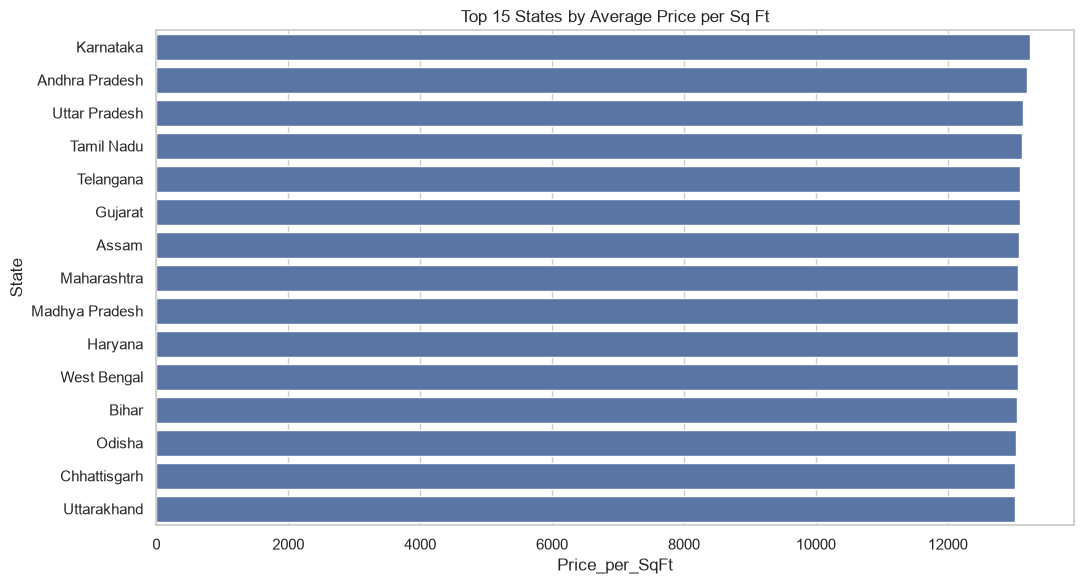

,City,Price_in_Lakhs
0,Bangalore,258.46
1,Surat,258.08
2,Kochi,257.42
3,Gaya,257.05
4,Mangalore,256.92
5,Dehradun,256.89
6,Mysore,256.85
7,Chennai,256.83
8,Hyderabad,256.59
9,Coimbatore,256.50


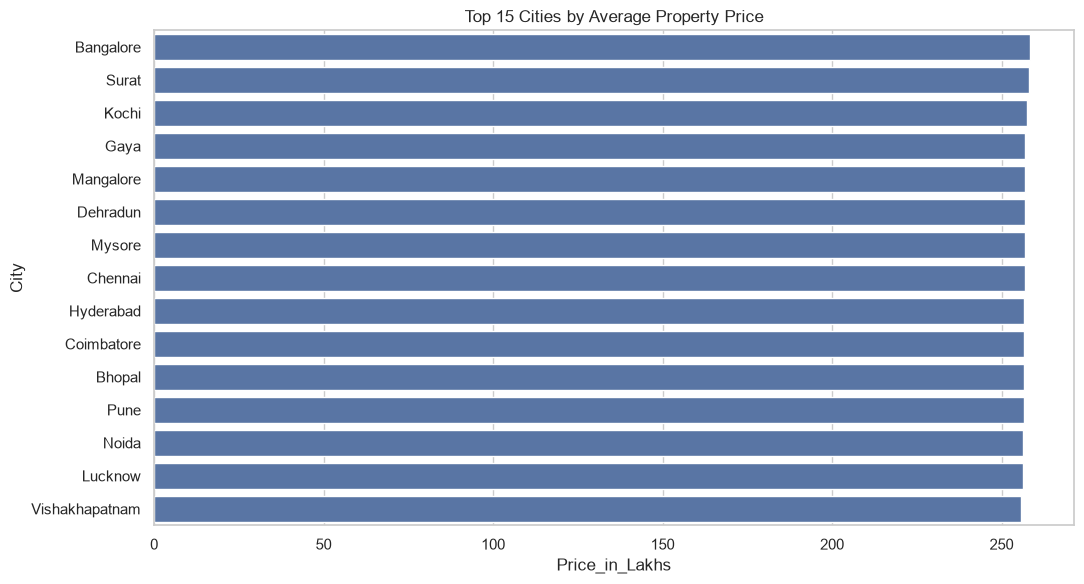

,Locality,Age_of_Property
0,Locality_10,18.00
1,Locality_105,19.00
2,Locality_11,19.00
3,Locality_218,19.00
4,Locality_238,19.00
5,Locality_405,19.00
6,Locality_316,19.00
7,Locality_296,19.00
8,Locality_438,19.00
9,Locality_321,19.00


BHK,1.00,2.00,3.00,4.00,5.00
City,,,,,
Ahmedabad,1264,1267,1272,1258,1350
Amritsar,1284,1239,1234,1224,1240
Bangalore,839,823,802,833,847
Bhopal,1238,1235,1255,1259,1297
Bhubaneswar,1236,1293,1299,1217,1278


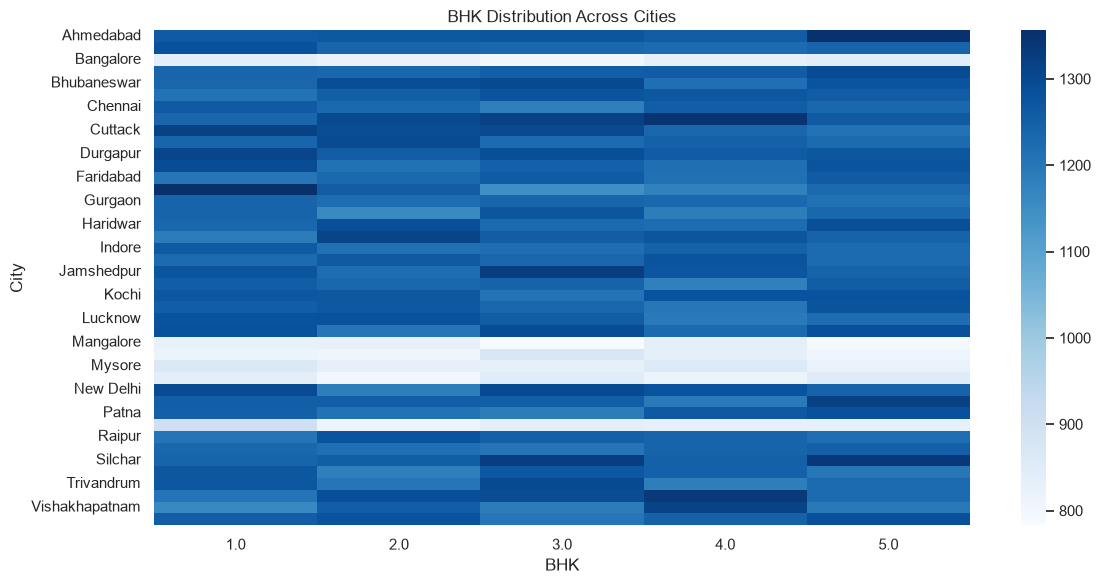

,Locality,Price_in_Lakhs
0,Locality_395,282.68
1,Locality_366,282.33
2,Locality_303,282.27
3,Locality_79,280.76
4,Locality_203,280.32


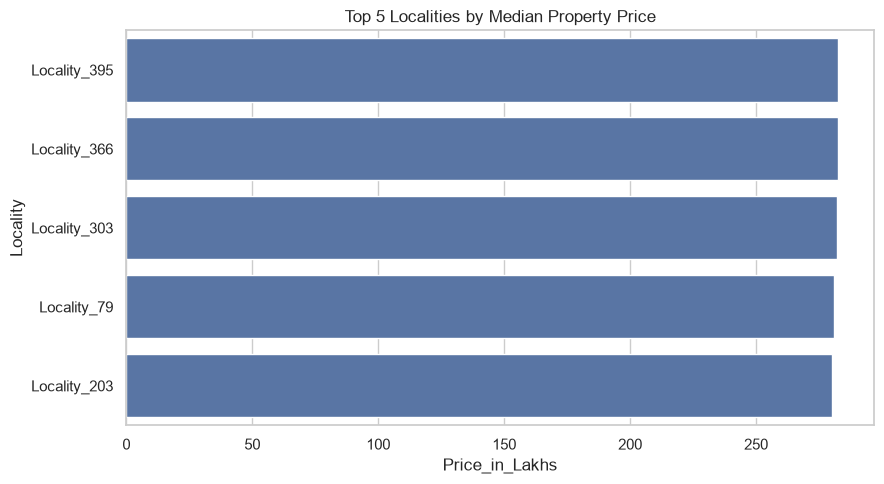

Note: the dataset has no transaction date/time field, so true price trends over time cannot be calculated.


In [6]:
# Q6. Average price per sq ft by state
state_ppsf = df.groupby("State", dropna=False)["Price_per_SqFt"].mean().sort_values(ascending=False).reset_index()
display(state_ppsf.head(15))
state_ppsf.to_csv(OUT / "avg_ppsf_by_state.csv", index=False)
plt.figure(figsize=(11, 6)); sns.barplot(data=state_ppsf.head(15), y="State", x="Price_per_SqFt")
plt.title("Top 15 States by Average Price per Sq Ft"); plt.tight_layout()
plt.savefig(FIG / "06_avg_ppsf_by_state.png", dpi=160); plt.show()

# Q7. Average property price by city
city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False).reset_index()
display(city_price.head(15)); city_price.to_csv(OUT / "avg_price_by_city.csv", index=False)
plt.figure(figsize=(11, 6)); sns.barplot(data=city_price.head(15), y="City", x="Price_in_Lakhs")
plt.title("Top 15 Cities by Average Property Price"); plt.tight_layout()
plt.savefig(FIG / "07_avg_price_by_city.png", dpi=160); plt.show()

# Q8. Median property age by locality (top 20 localities by number of records)
top_localities = df["Locality"].value_counts().head(20).index
locality_age = (df[df["Locality"].isin(top_localities)].groupby("Locality")["Age_of_Property"]
                .median().sort_values().reset_index())
display(locality_age); locality_age.to_csv(OUT / "median_age_by_locality.csv", index=False)

# Q9. BHK distribution across cities
bhk_city = pd.crosstab(df["City"], df["BHK"])
display(bhk_city.head())
bhk_city.to_csv(OUT / "bhk_distribution_by_city.csv")
plt.figure(figsize=(12, 6))
sns.heatmap(pd.crosstab(df["City"], df["BHK"]), cmap="Blues", linewidths=0)
plt.title("BHK Distribution Across Cities"); plt.tight_layout()
plt.savefig(FIG / "09_bhk_by_city.png", dpi=160); plt.show()

# Q10. Top 5 most expensive localities by median property price; this is cross-sectional, not a time trend.
top5_localities = (df.groupby("Locality")["Price_in_Lakhs"].median().nlargest(5).index)
locality_price = (df[df["Locality"].isin(top5_localities)].groupby("Locality")["Price_in_Lakhs"]
                  .median().sort_values(ascending=False).reset_index())
display(locality_price)
locality_price.to_csv(OUT / "top5_expensive_localities.csv", index=False)
plt.figure(figsize=(9, 5)); sns.barplot(data=locality_price, x="Price_in_Lakhs", y="Locality")
plt.title("Top 5 Localities by Median Property Price"); plt.tight_layout()
plt.savefig(FIG / "10_top_localities.png", dpi=160); plt.show()
print("Note: the dataset has no transaction date/time field, so true price trends over time cannot be calculated.")


## 6. EDA — questions 11–15: correlations, nearby facilities, furnishing and facing

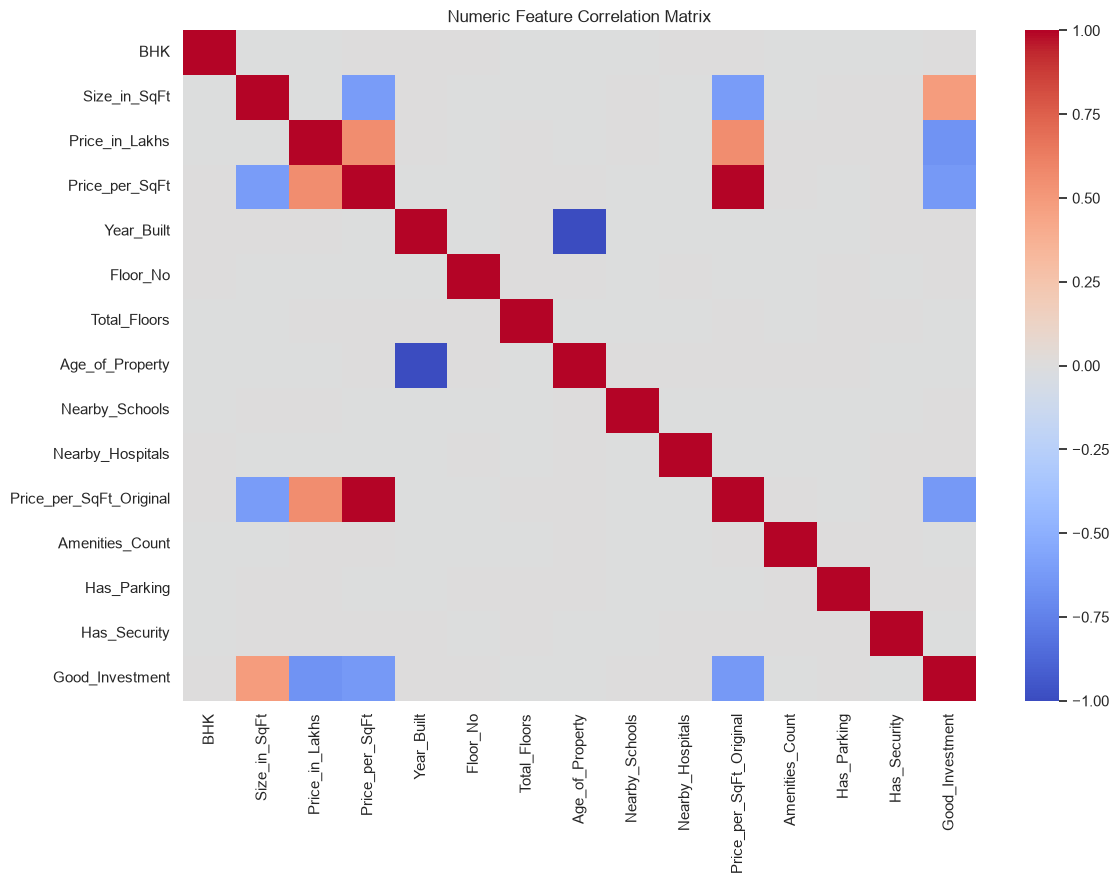

,Nearby_Schools,mean,median,count
0,1.00,"13,061.49","9,260.55",25360
1,2.00,"13,123.02","9,291.49",24851
2,3.00,"13,073.09","9,273.34",25045
3,4.00,"12,888.08","9,258.67",24739
4,5.00,"12,993.00","9,187.98",25023
5,6.00,"13,292.36","9,351.66",24824
6,7.00,"13,041.21","9,232.54",24808
7,8.00,"12,953.43","9,144.03",25290
8,9.00,"13,102.99","9,264.53",24823
9,10.00,"13,055.80","9,212.07",25237


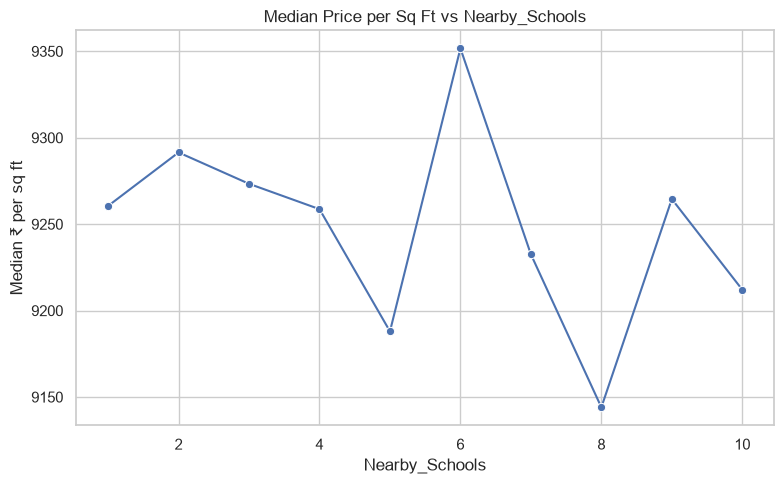

,Nearby_Hospitals,mean,median,count
0,1.00,"13,019.83","9,256.41",25075
1,2.00,"13,024.68","9,309.12",24960
2,3.00,"13,233.68","9,348.72",24834
3,4.00,"12,995.99","9,270.74",25168
4,5.00,"12,917.02","9,148.84",25102
5,6.00,"13,006.56","9,128.70",25082
6,7.00,"13,256.91","9,334.33",24887
7,8.00,"13,116.32","9,223.89",24891
8,9.00,"13,084.28","9,283.42",25014
9,10.00,"12,931.03","9,195.67",24987


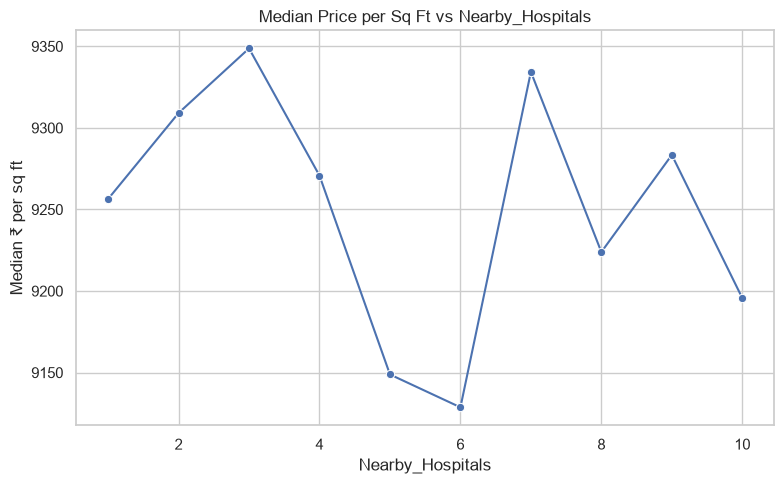

,Furnished_Status,mean,median,count
0,Furnished,254.45,253.56,83218
1,Semi-furnished,254.33,253.81,83374
2,Unfurnished,254.98,254.19,83408


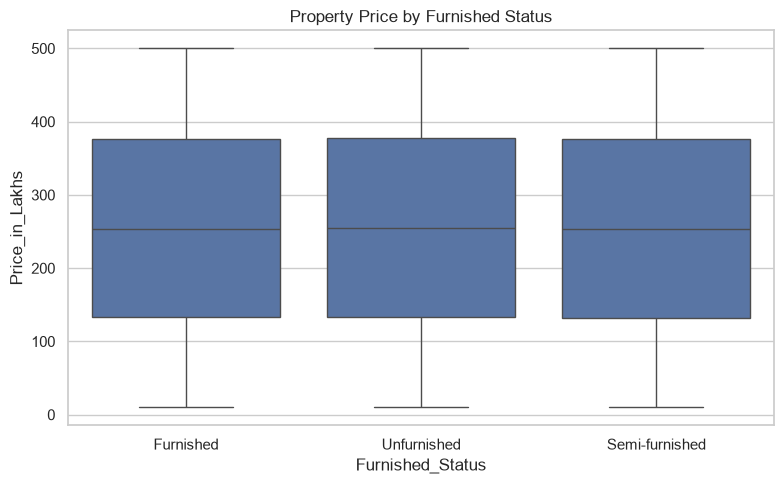

,Facing,mean,median,count
0,West,"13,140.02","9,307.59",62757
1,East,"13,023.70","9,234.01",62269
2,South,"13,044.11","9,224.63",62337
3,North,"13,024.87","9,219.23",62637


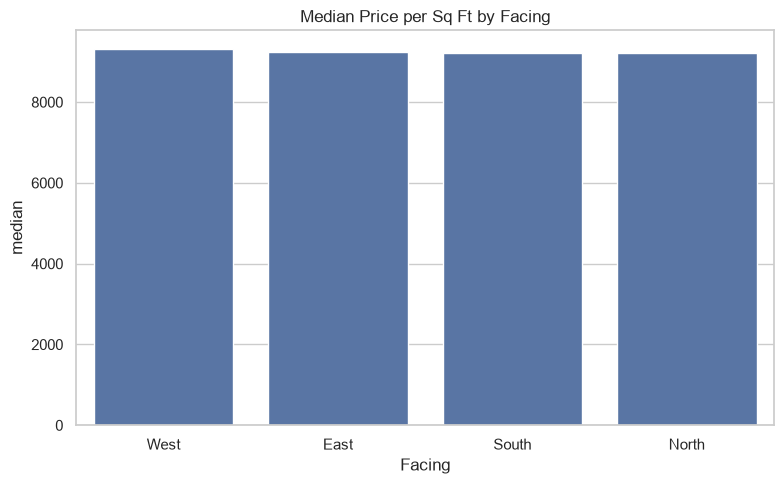

In [7]:
# Q11. Correlation among numeric features
numeric = df.select_dtypes(include=np.number).drop(columns=["ID"], errors="ignore")
corr = numeric.corr(numeric_only=True)
plt.figure(figsize=(12, 9)); sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Numeric Feature Correlation Matrix"); plt.tight_layout()
plt.savefig(FIG / "11_correlation_matrix.png", dpi=160); plt.show()
corr.to_csv(OUT / "numeric_correlations.csv")

# Q12–13. Schools/hospitals vs price per sq ft
for col, qnum in [("Nearby_Schools", 12), ("Nearby_Hospitals", 13)]:
    agg = df.groupby(col, dropna=False)["Price_per_SqFt"].agg(["mean", "median", "count"]).reset_index()
    display(agg)
    agg.to_csv(OUT / f"{col.lower()}_vs_ppsf.csv", index=False)
    plt.figure(figsize=(8, 5)); sns.lineplot(data=agg, x=col, y="median", marker="o")
    plt.title(f"Median Price per Sq Ft vs {col}"); plt.ylabel("Median ₹ per sq ft")
    plt.tight_layout(); plt.savefig(FIG / f"{qnum}_{col.lower()}_vs_ppsf.png", dpi=160); plt.show()

# Q14. Price by furnished status
furnishing = df.groupby("Furnished_Status")["Price_in_Lakhs"].agg(["mean", "median", "count"]).reset_index()
display(furnishing); furnishing.to_csv(OUT / "price_by_furnished_status.csv", index=False)
plt.figure(figsize=(8, 5)); sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", showfliers=False)
plt.title("Property Price by Furnished Status"); plt.tight_layout()
plt.savefig(FIG / "14_price_by_furnishing.png", dpi=160); plt.show()

# Q15. Price per sq ft by facing
facing = df.groupby("Facing")["Price_per_SqFt"].agg(["mean", "median", "count"]).sort_values("median", ascending=False).reset_index()
display(facing); facing.to_csv(OUT / "ppsf_by_facing.csv", index=False)
plt.figure(figsize=(8, 5)); sns.barplot(data=facing, x="Facing", y="median")
plt.title("Median Price per Sq Ft by Facing"); plt.tight_layout()
plt.savefig(FIG / "15_ppsf_by_facing.png", dpi=160); plt.show()


## 7. EDA — questions 16–20: ownership, availability, parking, amenities and transport

,Owner_Type,count
0,Broker,83479
1,Owner,83268
2,Builder,83253


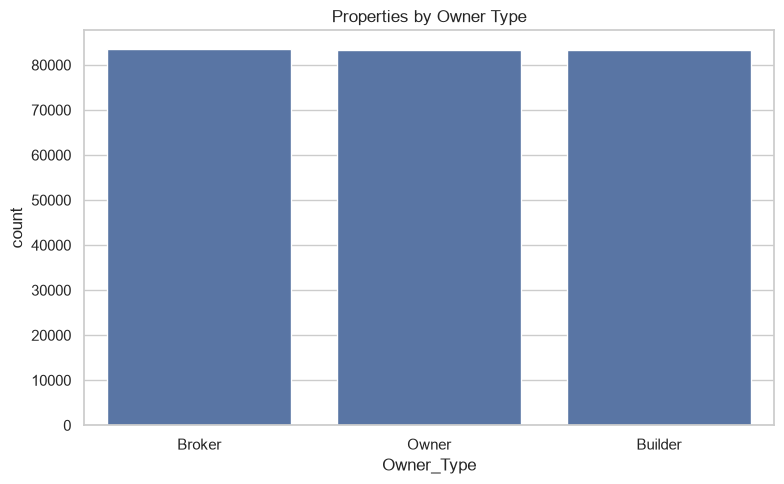

,Availability_Status,count
0,Under_Construction,125035
1,Ready_to_Move,124965


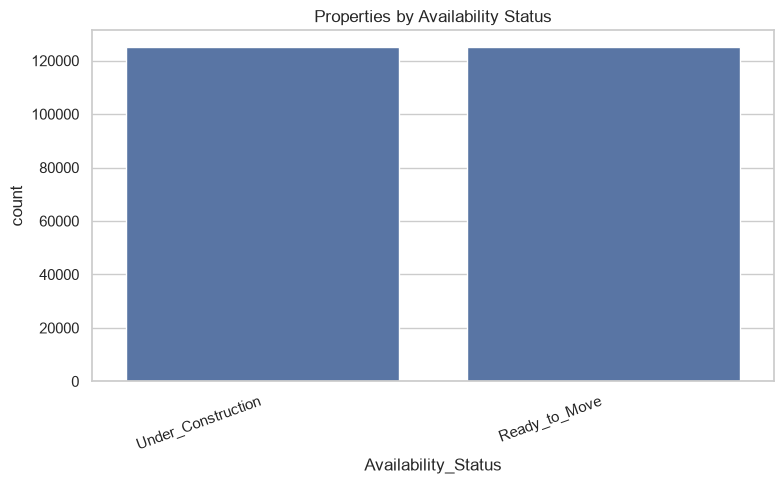

,Parking_Space,mean,median,count
0,No,254.43,253.37,125456
1,Yes,254.75,254.36,124544


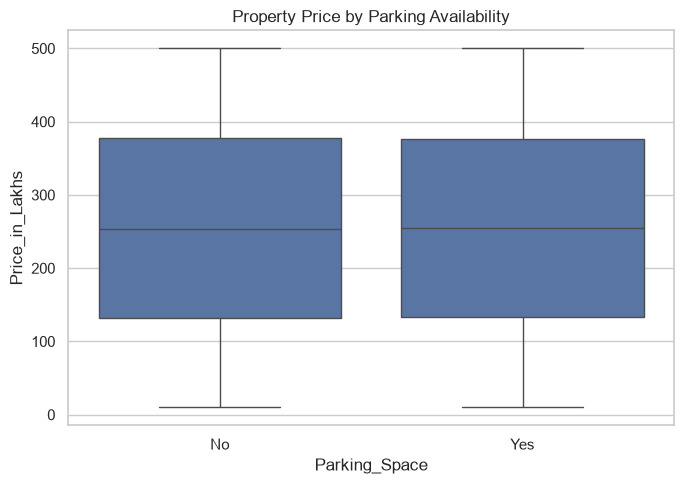

,Amenities_Count,mean,median,count
0,1,"13,015.00","9,240.31",50106
1,2,"13,059.41","9,241.96",49806
2,3,"13,044.05","9,206.73",49862
3,4,"13,070.87","9,249.82",50362
4,5,"13,102.17","9,293.66",49864


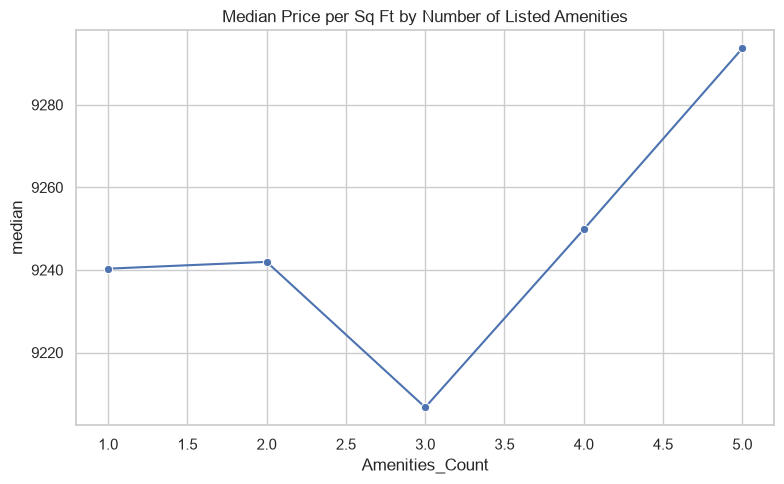

,Public_Transport_Accessibility,mean,median,count
0,High,"13,027.24","9,205.08",83705
1,Low,"13,085.54","9,265.33",83287
2,Medium,"13,062.23","9,269.31",83008


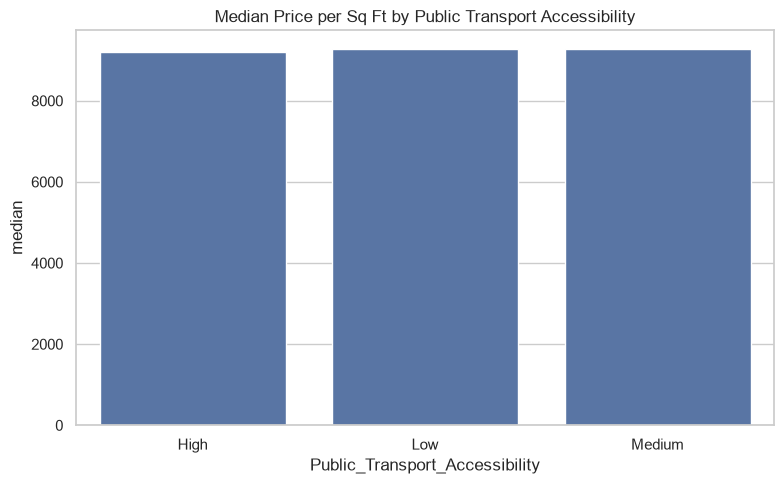

In [8]:
# Q16. Count by owner type
owner_counts = df["Owner_Type"].value_counts(dropna=False).rename_axis("Owner_Type").reset_index(name="count")
display(owner_counts); owner_counts.to_csv(OUT / "owner_type_counts.csv", index=False)
plt.figure(figsize=(8, 5)); sns.barplot(data=owner_counts, x="Owner_Type", y="count")
plt.title("Properties by Owner Type"); plt.tight_layout(); plt.savefig(FIG / "16_owner_type.png", dpi=160); plt.show()

# Q17. Availability status counts
availability = df["Availability_Status"].value_counts(dropna=False).rename_axis("Availability_Status").reset_index(name="count")
display(availability); availability.to_csv(OUT / "availability_counts.csv", index=False)
plt.figure(figsize=(8, 5)); sns.barplot(data=availability, x="Availability_Status", y="count")
plt.xticks(rotation=20, ha="right"); plt.title("Properties by Availability Status")
plt.tight_layout(); plt.savefig(FIG / "17_availability.png", dpi=160); plt.show()

# Q18. Parking vs property price
parking = df.groupby("Parking_Space")["Price_in_Lakhs"].agg(["mean", "median", "count"]).reset_index()
display(parking); parking.to_csv(OUT / "parking_vs_price.csv", index=False)
plt.figure(figsize=(7, 5)); sns.boxplot(data=df, x="Parking_Space", y="Price_in_Lakhs", showfliers=False)
plt.title("Property Price by Parking Availability"); plt.tight_layout()
plt.savefig(FIG / "18_parking_vs_price.png", dpi=160); plt.show()

# Q19. Amenities count vs price per sq ft
amenity_effect = df.groupby("Amenities_Count")["Price_per_SqFt"].agg(["mean", "median", "count"]).reset_index()
display(amenity_effect); amenity_effect.to_csv(OUT / "amenities_vs_ppsf.csv", index=False)
plt.figure(figsize=(8, 5)); sns.lineplot(data=amenity_effect, x="Amenities_Count", y="median", marker="o")
plt.title("Median Price per Sq Ft by Number of Listed Amenities")
plt.tight_layout(); plt.savefig(FIG / "19_amenities_vs_ppsf.png", dpi=160); plt.show()

# Q20. Transport accessibility vs price per sq ft
transport = df.groupby("Public_Transport_Accessibility")["Price_per_SqFt"].agg(["mean", "median", "count"]).reset_index()
display(transport); transport.to_csv(OUT / "transport_vs_ppsf.csv", index=False)
plt.figure(figsize=(8, 5)); sns.barplot(data=transport, x="Public_Transport_Accessibility", y="median")
plt.title("Median Price per Sq Ft by Public Transport Accessibility")
plt.tight_layout(); plt.savefig(FIG / "20_transport_vs_ppsf.png", dpi=160); plt.show()


## 8. Summary tables and hand-off to modeling
The notebook exports the cleaned data, audit tables, all EDA tables, and charts to `outputs/`. Review the output files before modeling. Important caveats:
- `Price_per_SqFt` is recalculated as `Price_in_Lakhs × 100,000 / Size_in_SqFt`, because price is in lakhs.
- The source dataset has no date/history column, so the requested “price trends over time” cannot be measured from these records. We compare expensive localities cross-sectionally instead.
- The `Good_Investment` label is a relative-price proxy, not a return/profit label.
- The project brief allows a fixed 8% annual appreciation assumption for five-year future value. This is a scenario calculation, not a model trained on observed five-year outcomes.